In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Read data file
df = pd.read_csv('salary_exp.csv')
df

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189


## Data Exploration & Preprocessing

In [4]:
df[5:]

,YearsExperience,Salary
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189
10,3.9,63218
11,4.0,55794
12,4.0,56957
13,4.1,57081
14,4.5,61111


In [5]:
df[5:10]

,YearsExperience,Salary
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189


In [6]:
df.iloc[2] #i=integer, loc=Location based index

YearsExperience        1.5
Salary             37731.0
Name: 2, dtype: float64

In [7]:
print(type(df))

<class 'pandas.DataFrame'>


In [8]:
# Initial 5 records
df.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


In [9]:
# Last 5 records
df.tail()

,YearsExperience,Salary
25,9.0,105582
26,9.5,116969
27,9.6,112635
28,10.3,122391
29,10.5,121872


In [10]:
# Retrieve random file
df.sample()

,YearsExperience,Salary
23,8.2,113812


In [11]:
df.sample(3)

,YearsExperience,Salary
15,4.9,67938
13,4.1,57081
20,6.8,91738


In [12]:
df.columns

Index(['YearsExperience', 'Salary'], dtype='str')

In [13]:
df.shape

(30, 2)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


In [15]:
# only show discriptive summary of Numerical column
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [16]:
df['YearsExperience'].describe()

count    30.000000
mean      5.313333
std       2.837888
min       1.100000
25%       3.200000
50%       4.700000
75%       7.700000
max      10.500000
Name: YearsExperience, dtype: float64

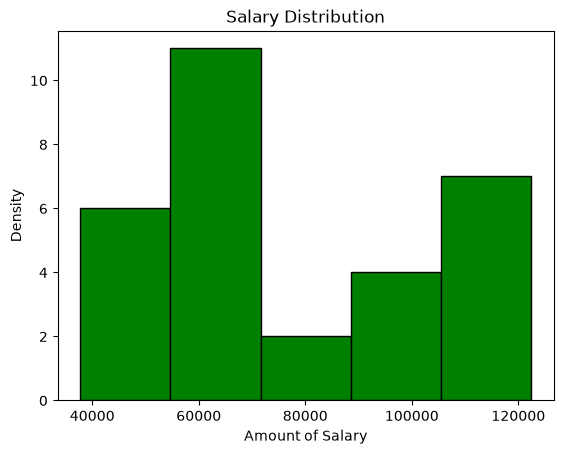

In [17]:
plt.title('Salary Distribution')
plt.xlabel('Amount of Salary')
plt.ylabel('Density')
plt.hist(df['Salary'],bins=5,edgecolor='black',color='green')
plt.show()

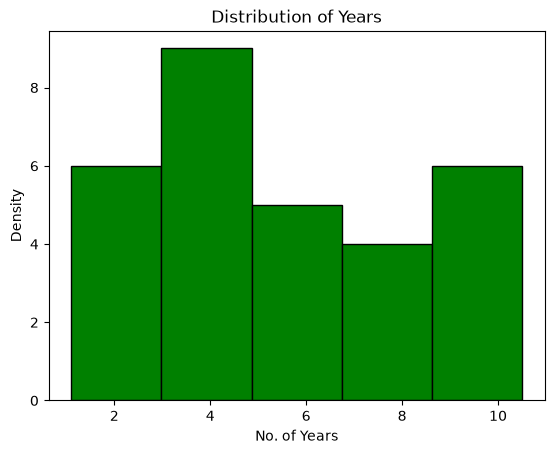

In [18]:
plt.title("Distribution of Years")
plt.xlabel("No. of Years")
plt.ylabel("Density")
plt.hist(df["YearsExperience"], bins=5,edgecolor="black", color="green")
plt.show()

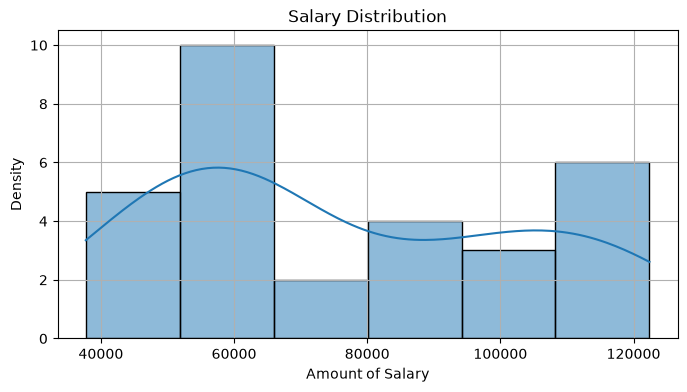

'It means that in addition to the histogram, Seaborn will plot a smooth curve that estimates the probability density function (PDF) \nof the salary values.\n\nHistogram → Shows the frequency of values in bins.\n\nKDE curve → A smooth approximation of the data distribution, making it easier to see the underlying pattern or trend.\n\nExample: If your salaries are clustered around a certain range, the KDE curve will peak in that area.'

In [19]:
# Univariate Analysis (One column)
plt.figure(figsize=(8,4))
plt.title('Salary Distribution')
plt.xlabel('Amount of Salary')
plt.ylabel('Density')
sns.histplot(df['Salary'],kde=True) # Kernel Density Estimate
plt.grid(True)
plt.savefig('salary_distribution_histogram.png')
plt.show()

"""It means that in addition to the histogram, Seaborn will plot a smooth curve that estimates the probability density function (PDF) 
of the salary values.

Histogram → Shows the frequency of values in bins.

KDE curve → A smooth approximation of the data distribution, making it easier to see the underlying pattern or trend.

Example: If your salaries are clustered around a certain range, the KDE curve will peak in that area."""

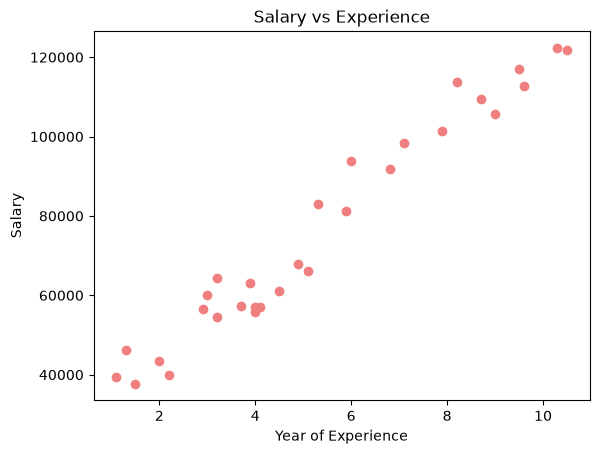

In [20]:
# Bivariate Analysis 
plt.scatter(df['YearsExperience'],df['Salary'],color='lightcoral')
plt.title("Salary vs Experience")
plt.xlabel('Year of Experience')
plt.ylabel('Salary')
plt.show()

In [21]:
correlation = df['YearsExperience'].corr(df['Salary'])
print('correlation b/w Experience and Salary',correlation)

correlation b/w Experience and Salary 0.9782416184887599


In [22]:
# Missing Value
df.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

In [23]:
X=df.drop(columns=["Salary"])
y=df['Salary']

In [25]:
X

,YearsExperience
0,1.1
1,1.3
2,1.5
3,2.0
4,2.2
5,2.9
6,3.0
7,3.2
8,3.2
9,3.7


In [24]:
y

0      39343
1      46205
2      37731
3      43525
4      39891
5      56642
6      60150
7      54445
8      64445
9      57189
10     63218
11     55794
12     56957
13     57081
14     61111
15     67938
16     66029
17     83088
18     81363
19     93940
20     91738
21     98273
22    101302
23    113812
24    109431
25    105582
26    116969
27    112635
28    122391
29    121872
Name: Salary, dtype: int64

In [25]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=45)

In [26]:
X_train

,YearsExperience
29,10.5
7,3.2
10,3.9
19,6.0
24,8.7
6,3.0
22,7.9
23,8.2
18,5.9
17,5.3


In [27]:
len(X_train)

24

In [28]:
X_test

,YearsExperience
16,5.1
27,9.6
25,9.0
5,2.9
13,4.1
9,3.7


In [29]:
len(X_test)

6

In [30]:
y_train

29    121872
7      54445
10     63218
19     93940
24    109431
6      60150
22    101302
23    113812
18     81363
17     83088
2      37731
12     56957
20     91738
26    116969
8      64445
14     61111
1      46205
15     67938
4      39891
28    122391
21     98273
0      39343
3      43525
11     55794
Name: Salary, dtype: int64

In [31]:
len(y_train)

24

In [32]:
y_test

16     66029
27    112635
25    105582
5      56642
13     57081
9      57189
Name: Salary, dtype: int64

In [33]:
len(y_test)

6

In [34]:
from sklearn.linear_model import LinearRegression

In [35]:
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression
reg = LinearRegression()

In [36]:
reg

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [37]:
reg.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9608.88]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.599e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [38]:
y_pred = reg.predict(X_test)
y_pred

array([ 74997.87116706, 118237.8380738 , 112472.5091529 ,  53858.33179043,
        65388.98963223,  61545.4370183 ])

In [39]:
pd.DataFrame({'y_test':y_test, 'y_pred':y_pred,'MAE':(y_test-y_pred)})

,y_test,y_pred,MAE
16,66029,74997.871167,-8968.871167
27,112635,118237.838074,-5602.838074
25,105582,112472.509153,-6890.509153
5,56642,53858.331790,2783.668210
13,57081,65388.989632,-8307.989632
9,57189,61545.437018,-4356.437018


In [40]:
from sklearn.metrics import mean_squared_error, r2_score

In [42]:
print('MSE = ', mean_squared_error(y_test, y_pred ))
print('RMSE = ', np.sqrt(mean_squared_error(y_test, y_pred )))
print('R2 = ', r2_score(y_test, y_pred ))

MSE =  42510267.467214905
RMSE =  6519.989836434939
R2 =  0.9250487875802145


In [43]:
"""[[10]] → a 2D array (one sample with one feature value = 10).

Returns → the predicted y value based on the model's learned coefficients and intercept."""

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

reg.predict([[10]])


array([122081.39068773])

In [44]:
reg.predict([[25]])

array([266214.61371019])

In [45]:
print ("Intercept value:",reg.intercept_)
print ("Slope value:",reg.coef_)
print("y= mX","+","C")
print("y=",reg.coef_,"*",+reg.intercept_)

Intercept value: 25992.575339423667
Slope value: [9608.88153483]
y= mX + C
y= [9608.88153483] * 25992.575339423667


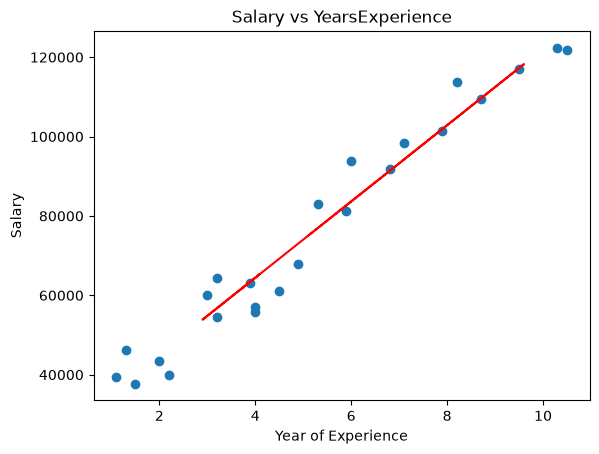

In [46]:
plt.scatter(X_train,y_train)
plt.plot(X_test,y_pred,color='r')
plt.title("Salary vs YearsExperience")
plt.xlabel("Year of Experience")
plt.ylabel("Salary")
plt.show()

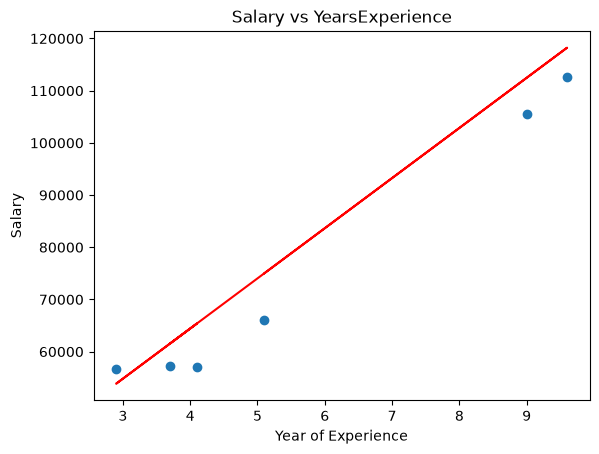

In [47]:
plt.scatter(X_test,y_test)
plt.plot(X_test,y_pred,color='r')
plt.title("Salary vs YearsExperience")
plt.xlabel("Year of Experience")
plt.ylabel("Salary")
plt.show()